In [18]:
from rdkit import Chem
from rdkit.Chem import rdDetermineBonds
from rdkit.Chem import Draw
from rdkit.Chem import AllChem
import py3Dmol
from IPython.display import display

from openbabel import pybel


In [19]:
XYZ_File = '/home/uqjzuegg/Data/Metal/Renamed/C0236992.xyz'
XYZ_File = '/home/uqjzuegg/Data/Metal/test.xyz'

SMI = 'Cc1ccc([B-]23c4cccc5[B-]6(c7ccc(C)cc7)n7cccn7->[Sc+3](<-n45)(<-n4cccn42)(<-n2cccn23)(<-n2cccn26)<-O2CCCC2)cc1'
SMI = 'Nc1ccc(c(c1)F)C(=O)O[Lu](OC(=O)c1ccc(cc1F)N)(OC(=O)c1ccc(cc1F)N)([OH2])[OH2]'
# RDKit
# raw_mol = Chem.MolFromXYZFile(XYZ_File)
# mol = Chem.Mol(raw_mol)
# molblock = Chem.MolToMolBlock(mol)
# rdDetermineBonds.DetermineBonds(mol, charge=0)
#display(Draw.MolToImage(mol))

# OpenBabel
opmol = next(pybel.readfile("xyz", XYZ_File))
opmolblock = opmol.write("mol")
opsmiles = opmol.write("smi").strip()
print(opsmiles)


[Sc]1234[N@@]5[CH]C=CN5[B@](c5ccc(cc5)C)([C]5C=CC=C([B@@](c6ccc(cc6)C)(N6C=C[CH][N@@]36)[N@]3[CH]C=CN43)N25)[N@@]2[CH]C=CN12.O1CCCC1	CSD_code = VUCVUN | q = 1 | S = 0 | Stoichiometry = C35H37B2N9OSc(1+) | MND = 6 | 2020-2024 CSD


*** Open Babel Warning  in PerceiveBondOrders
  Failed to kekulize aromatic bonds in OBMol::PerceiveBondOrders (title is CSD_code = VUCVUN | q = 1 | S = 0 | Stoichiometry = C35H37B2N9OSc(1+) | MND = 6 | 2020-2024 CSD)



In [20]:
view = py3Dmol.view(width=400, height=300)
view.addModel(opmolblock, "mol")
view.setStyle({"stick": {}})
view.zoomTo()
view.show()

3Dmol.js failed to load for some reason. Please check your browser console for error messages.

In [21]:
from rdkit import Chem

METAL_NUMS = (
    set(range(21, 31))
    | set(range(39, 49))
    | set(range(57, 81))
    | set(range(89, 113))
)

BIDENTATE_RULES = [
    ("picolinate", "[OX2:1]([*:2])[CX3](=[OX1])c1[nX2:3]cccc1"),
    ("amino_acidate", "[OX2:1]([*:2])[CX3](=[OX1])[CX4][NX3H2:3]"),
    ("beta_diketonate", "[OX2:1]([*:2])[CX3]=[CX3][CX3]=[OX1:3]"),
    ("salicylaldehyde", "[OX2:1]([*:2])c1ccccc1[CX3]=[OX1:3]"),
    ("bipyridine", "[nX3:1]([*:2])1ccccc1-c2[nX2:3]cccc2"),
    ("phenanthroline", "[nX3:1]([*:2])1cccc2ccc3ccc[nX2:3]c3c12"),
    ("ethylenediamine", "[NX4:1]([*:2])[CX4][CX4][NX3H2:3]"),
    ("carboxylate", "[OX2:1]([*:2])[CX3]=[OX1:3]"),
    ("nitrate", "[OX2:1]([*:2])[NX3](=[OX1])=[OX1:3]"),
    ("carbamate", "[OX2,SX2:1]([*:2])[CX3]([NX3])=[OX1,SX1:3]"),
]

COMPILED_BIDENTATE_RULES = [
    (name, Chem.MolFromSmarts(smarts)) for name, smarts in BIDENTATE_RULES
]


def is_metal(atom: Chem.Atom) -> bool:
    return atom.GetAtomicNum() in METAL_NUMS


def _convert_neutral_monodentate_to_dative(rw_mol: Chem.RWMol) -> None:
    for bond in list(rw_mol.GetBonds()):
        a1, a2 = bond.GetBeginAtom(), bond.GetEndAtom()
        if not (is_metal(a1) ^ is_metal(a2)):
            continue

        metal = a1 if is_metal(a1) else a2
        donor = a2 if is_metal(a1) else a1

        if donor.GetFormalCharge() != 0:
            continue

        atomic_num = donor.GetAtomicNum()
        degree = donor.GetDegree()
        # Use GetNumExplicitHs() + GetNumImplicitHs() safely after UpdatePropertyCache(strict=False)
        total_hs = donor.GetTotalNumHs()

        is_neutral_o = atomic_num == 8 and (total_hs + degree) == 3
        is_neutral_n = atomic_num == 7 and (
            (not donor.GetIsAromatic() and (total_hs + degree) == 4)
            or (donor.GetIsAromatic() and degree == 3)
        )
        is_neutral_p = atomic_num == 15 and (total_hs + degree) == 4

        if is_neutral_o or is_neutral_n or is_neutral_p:
            idx_d, idx_m = donor.GetIdx(), metal.GetIdx()
            rw_mol.RemoveBond(idx_d, idx_m)
            rw_mol.AddBond(idx_d, idx_m, Chem.BondType.DATIVE)


def standardize_metal_complex(
    smiles: str,
    enable_bidentate: bool = True,
    max_cn: int = 12,
) -> str:
    mol = Chem.MolFromSmiles(smiles, sanitize=False)
    if mol is None:
        raise ValueError(f"Invalid SMILES: {smiles}")

    rw_mol = Chem.RWMol(mol)

    # REQUIRED: Compute implicit/explicit valences non-strictly before calling GetTotalNumHs()
    rw_mol.UpdatePropertyCache(strict=False)

    # Step 1: Fix neutral monodentate donors
    _convert_neutral_monodentate_to_dative(rw_mol)
    rw_mol.UpdatePropertyCache(strict=False)
    Chem.FastFindRings(rw_mol)

    # Step 2: Apply bidentate chelation rules in priority order
    if enable_bidentate:
        chelated_primary_donors = set()

        for rule_name, patt in COMPILED_BIDENTATE_RULES:
            matches = rw_mol.GetSubstructMatches(patt)
            for match in matches:
                atom_map = {}
                for query_idx, mol_idx in enumerate(match):
                    map_num = patt.GetAtomWithIdx(query_idx).GetAtomMapNum()
                    if map_num:
                        atom_map[map_num] = mol_idx

                primary_idx = atom_map[1]
                metal_idx = atom_map[2]
                secondary_idx = atom_map[3]

                metal_atom = rw_mol.GetAtomWithIdx(metal_idx)
                secondary_atom = rw_mol.GetAtomWithIdx(secondary_idx)

                if not is_metal(metal_atom):
                    continue
                if primary_idx in chelated_primary_donors:
                    continue
                if metal_atom.GetDegree() >= max_cn:
                    continue
                if rw_mol.GetBondBetweenAtoms(secondary_idx, metal_idx) is not None:
                    continue
                if any(is_metal(nbr) for nbr in secondary_atom.GetNeighbors()):
                    continue

                rw_mol.AddBond(secondary_idx, metal_idx, Chem.BondType.DATIVE)
                chelated_primary_donors.add(primary_idx)
                rw_mol.UpdatePropertyCache(strict=False)

    # Step 3: Sanitize and return canonical SMILES
    fixed_mol = rw_mol.GetMol()
    Chem.SanitizeMol(fixed_mol)
    return Chem.MolToSmiles(fixed_mol)

examples = {
    "Lu-benzoate (bidentate carboxylate + aqua)": (
        "Nc1ccc(c(c1)F)C(=O)O[Lu](OC(=O)c1ccc(cc1F)N)(OC(=O)c1ccc(cc1F)N)([OH2])[OH2]"
    ),
    "Eu-picolinate (5-membered N,O prioritized over 4-membered O,O)": (
        "O=C(O[Eu](OC(=O)c1ccccn1)(OC(=O)c1ccccn1)([OH2])[OH2])c1ccccn1"
    ),
    "Cu-bipyridine dichloride (neutral N,N-chelate)": (
        "c1cccn1[Cu](Cl)(Cl)-c1ccccn1"
    ),
}

Nc1ccc(C2[O][Lu]34(<-[OH2])(<-[OH2])([O]C(=[O]->3)c3ccc(N)cc3F)([O]C(=[O]->4)c3ccc(N)cc3F)<-[O]=2)c(F)c1


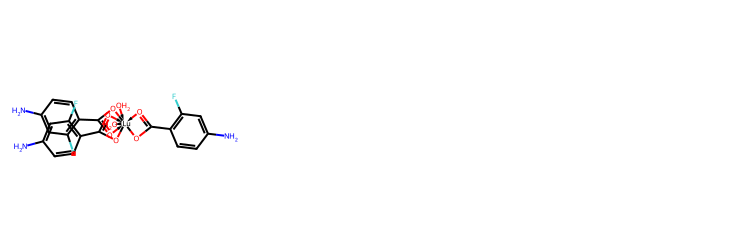

In [26]:
sSMI = standardize_metal_complex(SMI)

rdmol = Chem.MolFromSmiles(sSMI)
AllChem.Compute2DCoords(rdmol)
rdmolblock = Chem.MolToMolBlock(rdmol)
print(Chem.MolToSmiles(rdmol))

# view = py3Dmol.view(width=400, height=300)
# view.addModel(rdmolblock, "mol")
# view.setStyle({"stick": {}})
# view.zoomTo()
# view.show()

#IPythonConsole.drawOptions.clearBackground = True
Draw.MolsToGridImage([rdmol], molsPerRow=3, subImgSize=(250, 250))

In [ ]:

mol_h = Chem.AddHs(rdmol)


lu_indices = [a.GetIdx() for a in mol_h.GetAtoms() if a.GetAtomicNum() == 71]
for idx in lu_indices:
    #mol_h.GetAtomWithIdx(idx).SetAtomicNum(39)  # Yttrium (similar ionic radius to Lu3+)
    mol_h.GetAtomWithIdx(idx).SetAtomicNum(57)  # La (similar ionic radius to Lu3+)

Chem.SanitizeMol(mol_h)
AllChem.EmbedMolecule(mol_h, randomSeed=42)
AllChem.UFFOptimizeMolecule(mol_h, maxIters=500)

# 3. Restore Lutetium (71)
for idx in lu_indices:
    mol_h.GetAtomWithIdx(idx).SetAtomicNum(71)


# status = AllChem.EmbedMolecule(mol_h, randomSeed=42)

# if status == 0:
#     # Use UFF rather than MMFF94 for metal-containing species
#     AllChem.UFFOptimizeMolecule(mol_h, maxIters=500)#print(Chem.MolToSmiles(rdmol))
    
molhblock = Chem.MolToMolBlock(mol_h)
print(Chem.MolToSmiles(mol_h))

view = py3Dmol.view(width=400, height=300)
view.addModel(molhblock, "mol")
view.setStyle({"stick": {}})
view.zoomTo()
view.show()


# Optimize Outside RDKit:
# UFF parameters for lanthanides are notoriously stiff and inaccurate for 8- or 9-coordinate complexes 
# (the most common coordination numbers for \(\text{Lu}^{3+}\)). 
# Use RDKit only to generate an initial rough 3D guess (via the surrogate trick above) and relax the 
# final geometry with GFN2-xTB (with --alpb or --gbsa solvent if needed) or DFT.

[H]c1c([H])c(N([H])[H])c([H])c(F)c1C1[O][Lu]23([O]C(=[O]->2)c2c([H])c([H])c(N([H])[H])c([H])c2F)([O]C(=[O]->3)c2c([H])c([H])c(N([H])[H])c([H])c2F)(<-[O]=1)(<-[O]([H])[H])<-[O]([H])[H]


[17:03:25] UFFTYPER: Unrecognized charge state for atom: 7
[17:03:25] UFFTYPER: Unrecognized atom type: La6+3 (7)
[17:03:25] UFFTYPER: Unrecognized charge state for atom: 7
[17:03:25] UFFTYPER: Unrecognized atom type: La6+3 (7)


3Dmol.js failed to load for some reason. Please check your browser console for error messages.